# Four-class BiLSTM activity classifier

This notebook trains a bidirectional-LSTM model to classify `sitting`, `standing`, `walking`, and the `sit-stand` transition from accelerometer and gyroscope recordings.

Place labelled CSV files in `data/training`. Each needs: `timestamp, ax, ay, az, gx, gy, gz, label`. The companion `TensorFlow_ML_Algo.py` file contains the reusable loading, model, metrics, and plot functions.

In [1]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from IPython.display import Image, display

from TensorFlow_ML_Algo import load_training_data, make_model, metrics, save_model

In [2]:
# Load the four annotated activities and create a held-out validation split.
x, y, labels = load_training_data('data/training', sample_hz=50, seconds=2.56, overlap=0)
rng = np.random.default_rng(42)
indices = rng.permutation(len(x))
split = round(len(x) * 0.2)
validation, training = indices[:split], indices[split:]
mean, std = x[training].mean(axis=(0, 1)), x[training].std(axis=(0, 1))
std = np.maximum(std, 1e-6)
x = (x - mean) / std
labels

['sit-stand', 'sitting', 'standing', 'walking']

In [3]:
# Train the bidirectional-LSTM for 20 epochs.
tf.keras.utils.set_random_seed(42)
model = make_model(x.shape[1], len(labels))
history = model.fit(
    x[training], y[training],
    validation_data=(x[validation], y[validation]),
    epochs=20, batch_size=32, verbose=2
)

Epoch 1/20
9/9 - 4s - 400ms/step - accuracy: 0.7248 - loss: 1.1693 - val_accuracy: 0.8594 - val_loss: 0.9719
Epoch 2/20
9/9 - 0s - 52ms/step - accuracy: 0.9457 - loss: 0.6781 - val_accuracy: 0.8594 - val_loss: 0.6811
Epoch 3/20
9/9 - 0s - 48ms/step - accuracy: 0.9457 - loss: 0.3910 - val_accuracy: 0.8906 - val_loss: 0.4501
Epoch 4/20
9/9 - 0s - 48ms/step - accuracy: 0.9690 - loss: 0.1997 - val_accuracy: 0.9375 - val_loss: 0.2488
Epoch 5/20
9/9 - 0s - 45ms/step - accuracy: 1.0000 - loss: 0.0765 - val_accuracy: 0.9688 - val_loss: 0.1798
Epoch 6/20
9/9 - 0s - 42ms/step - accuracy: 1.0000 - loss: 0.0312 - val_accuracy: 0.9531 - val_loss: 0.1586
Epoch 7/20
9/9 - 0s - 44ms/step - accuracy: 1.0000 - loss: 0.0165 - val_accuracy: 0.9531 - val_loss: 0.1615
Epoch 8/20
9/9 - 0s - 46ms/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 0.9531 - val_loss: 0.1643
Epoch 9/20
9/9 - 0s - 45ms/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 0.9531 - val_loss: 0.1658
Epoch 10/20
9/9 - 0s - 47ms

In [1]:
# Evaluate, save the model, and generate the epoch graph and heatmap.
%pip install matplotlib
predicted = model.predict(x[validation], verbose=0).argmax(axis=1)
results = metrics(y[validation], predicted, labels)
weights = save_model(
    model, 'models/phone_activity_4class.weights.h5', labels,
    50, 2.56, 0, mean, std, results, history
)
results

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


NameError: name 'model' is not defined

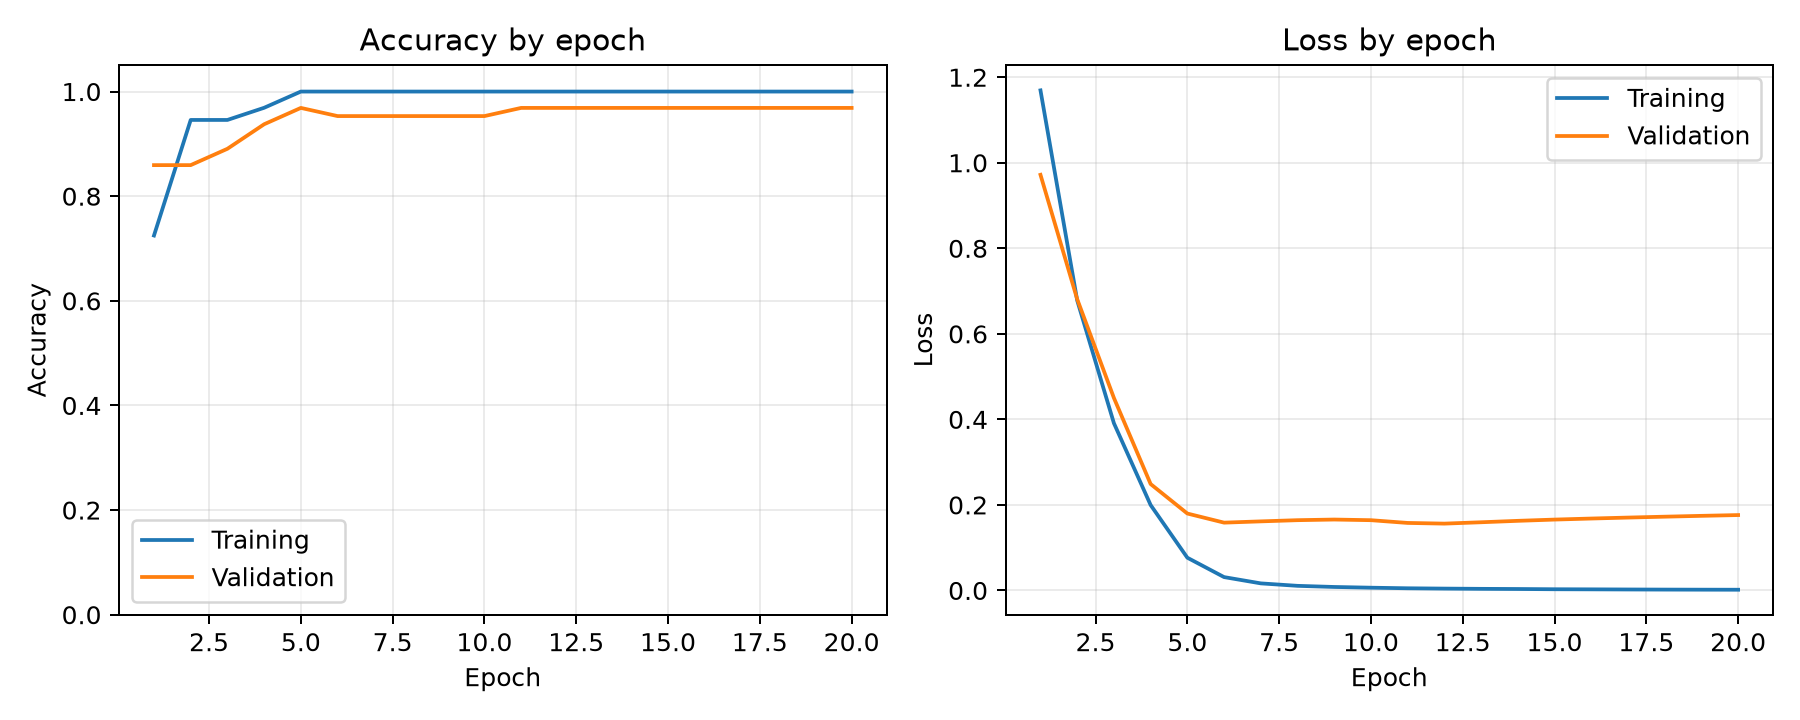

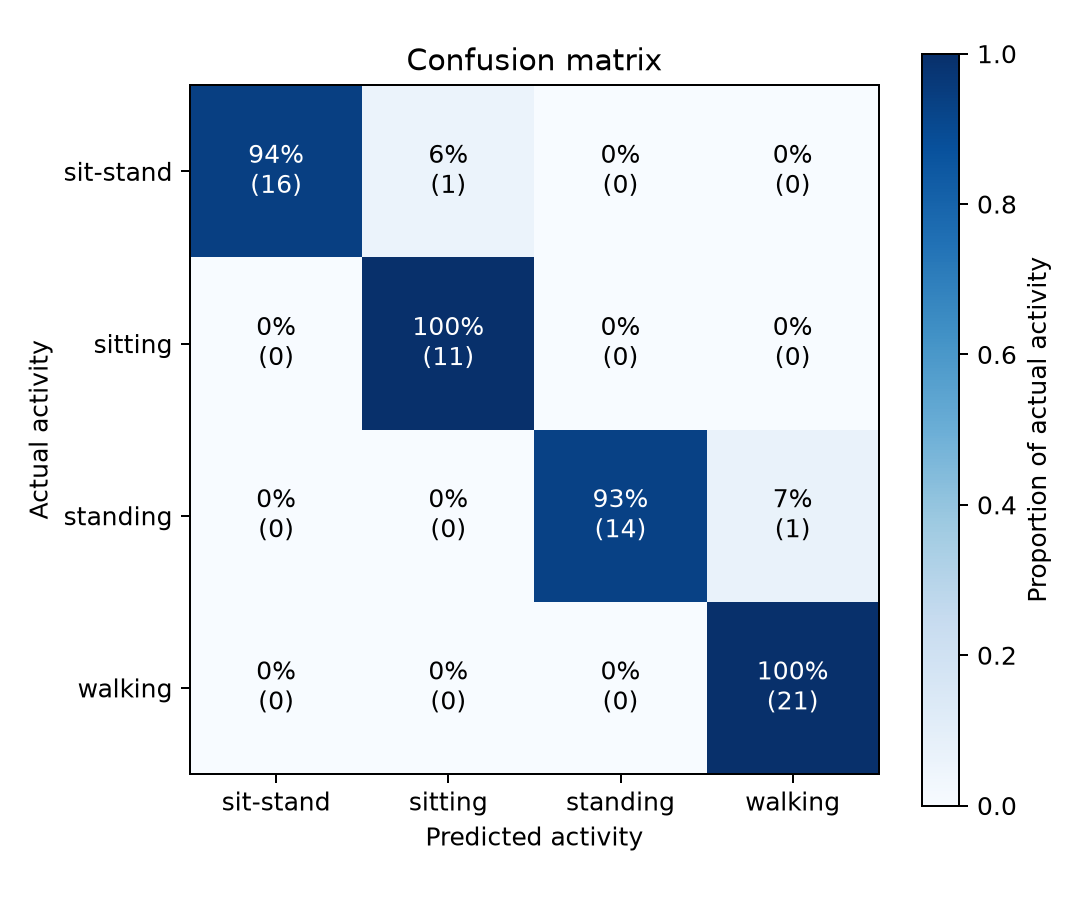

In [9]:
display(Image(filename=str(weights.with_suffix('.epochs.png'))))
display(Image(filename=str(weights.with_suffix('.confusion.png'))))